# Magnetostatics with the scalar potential: a coil on a closed iron frame (PHI3D_nodal)

This notebook follows `examples/core_3D_phi`. A coil is wound on one leg of a closed square iron frame; we solve the
static field with the element type **PHI3D_nodal**:

$$\mathbf{H}=\mathbf{H}_s-\nabla\phi,\qquad \nabla\times\mathbf{H}_s=\mathbf{J}_s,\qquad
\nabla\cdot\mu(\mathbf{H}_s-\nabla\phi)=0 ,$$

with the reduced scalar potential $\phi$ (`PHI`, nodal) and the source field $\mathbf{H}_s$ (`Hs`, edge elements)
both unknowns of **one** system. Why this model:

* an iron loop around a current is the case where the classical reduced potential (a Biot-Savart $\mathbf{H}_s$ given
  per cell) loses its accuracy: in the iron $\mathbf{H}\approx0$, so $\mathbf{H}_s$ and $\nabla\phi$ nearly cancel, and
  if they are not in the same discrete space the cancellation error dominates. Here they are: the gradients of
  first-order Lagrange functions are edge (Nedelec) functions;
* $\phi$ stays single valued: $\mathbf{H}_s$ carries the current, no cut is needed.

The notebook shows:

1. the model, the source current `Js` and the gauge of $\mathbf{H}_s$;
2. the magnetization curve of the frame with a B-H curve (Newton, static load steps), against a linear iron and a
   magnetic-circuit estimate;
3. the alternative of an $\mathbf{H}_s$ **given on the edges** (the circulations of a known field: only $\phi$ is
   solved);
4. the field in the saturated frame.

See the user manual (*Element library: PHI3D_nodal*, *Nonlinear laws*) and the theory (*Scalar potentials*).

In [1]:
import contextlib, io, os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection, tree_gauge
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # the job log keeps everything (<model>.log in the working folder)
MU0 = 4e-7 * np.pi
QUIET = {"-ksp_monitor": None, "-ksp_view": None, "-ksp_converged_reason": None, "-log_view": None,
         "-ksp_monitor_true_residual": None, "-ksp_monitor_solution": None}   # no PETSc reports in the notebook

import sys
sys.path.insert(0, os.getcwd())               # docs/tutorials: the plotting helpers of the notebooks
from setup_views import view                  # regions, selected nodes and edges of a setup step
EXAMPLES = Path("../../examples").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_core_3D_phi_"))
for case in ("core_3D_phi",):
    folder = EXAMPLES / case
    for f in (case + ".vtu", "model_data.json"):
        shutil.copy(folder / f, WORK / f"{case}_{f}" if f == "model_data.json" else WORK / f)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

def quietly():
    """Keep the report tables of the solver (and libMesh's Newton trace) out of the notebook: they are in the job log."""
    return contextlib.redirect_stdout(io.StringIO())

def new_solver(case, log):
    """A solver on the example's mesh and model data (model_data.json copied as <case>_model_data.json)."""
    solver = Solver(log_file=log)
    solver.read_model(case + ".vtu")
    solver.model.read_json(case + "_model_data.json")
    solver.solver_settings = {"petsc_options": QUIET}
    return solver

def select_surface(grid, conductor, others, midside):
    """Select the points shared by the cells of TYPE ``conductor`` and those of TYPEs ``others`` (the surface of the
    conductor): its midside points (midside=True: the edge DOFs) or its corner points."""
    selection.select(grid, "TYPE", conductor, location="elem"); selection.nsle(grid)
    selection.select(grid, "TYPE", list(others), location="elem"); selection.nsle(grid, mode="r")
    selection.select(grid, "MidsideNodes", int(midside), mode="r")

def select_inside(grid, conductor, others):
    """Select the corner points of the cells of TYPE ``conductor`` that no cell of TYPEs ``others`` has."""
    selection.select(grid, "TYPE", conductor, location="elem"); selection.nsle(grid)
    selection.select(grid, "TYPE", list(others), location="elem"); selection.nsle(grid, mode="u")
    selection.select(grid, "MidsideNodes", 0, mode="r")

working in a temporary folder: pytec3d_core_3D_phi_t0xcxkiu


## The model

The box |x|, |y| < 2 m, |z| < 1.5 m, 3072 HEX20 cells of 0.25 m (`examples/files/formulation_meshes.py`). The frame
(TYPE 2, `SOFT_MAGNETIC`) is 0.5 < max(|x|, |y|) < 1 m, |z| < 0.5 m: legs of 0.5 x 1 m section, a mean magnetic path
of about 6 m. The coil (TYPE 3, `STRANDED_CONDUCTOR`) is a 0.25 m thick winding around the leg 0.5 < x < 1 m, over
|y| < 0.5 m. All three TYPE rows are `PHI3D_nodal` with `option2` = 1: the type is first order only.

{"1": {"element_type": "PHI3D_nodal", "option1": "NON_CONDUCTING", "option2": 1}, "2": {"element_type": "PHI3D_nodal", "option1": "SOFT_MAGNETIC", "option2": 1}, "3": {"element_type": "PHI3D_nodal", "option1": "STRANDED_CONDUCTOR", "option2": 1}}
3072 cells, cells per TYPE: {np.int32(1): np.int64(2816), np.int32(2): np.int64(192), np.int32(3): np.int64(64)}


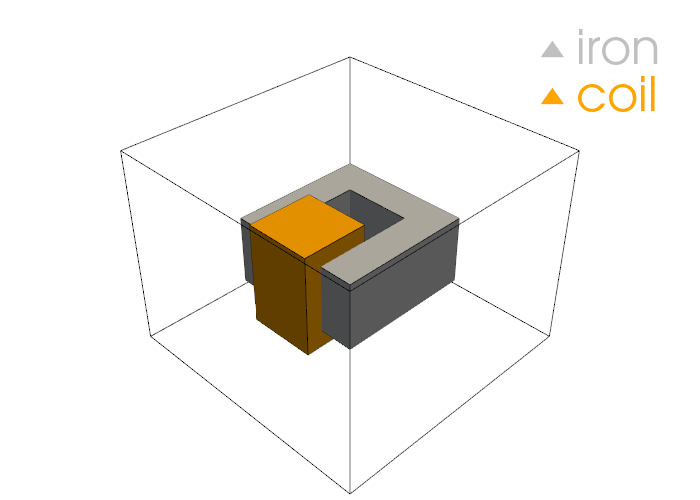

In [2]:
import json
print(json.dumps(json.load(open("core_3D_phi_model_data.json"))["element_types"]))
grid = pv.wrap(meshes.read_mesh("core_3D_phi.vtu"))
print(grid.n_cells, "cells, cells per TYPE:", dict(zip(*np.unique(grid.cell_data["TYPE"], return_counts=True))))

p = pv.Plotter(window_size=(700, 500))
for t, color, label in ((2, "silver", "iron"), (3, "orange", "coil")):
    part = grid.threshold((t, t), scalars="TYPE")
    p.add_mesh(part, color=color, label=label)
    p.add_mesh(part.extract_feature_edges(), color="black")
p.add_mesh(grid.outline(), color="black")
p.add_legend(); p.view_isometric(); p.show()

## The source current and the gauge of Hs

`Js` is a cell array of the `STRANDED_CONDUCTOR` cells. The current circulates about +y around the leg; per
ampere-turn its density is $J_0=1/(0.25\times1.0)$ A/m². The corner cells of the winding take half of each direction:
that cell-wise `Js` is not exactly divergence-free, and need not be. The weak form of $\mathbf{H}_s$,
$\int\nabla\times\mathbf{h}\cdot\nabla\times\mathbf{H}_s=\int\nabla\times\mathbf{h}\cdot\mathbf{J}_s$, only sees the
solenoidal part of `Js`; the element output `Jt` $=\nabla\times\mathbf{H}_s$ shows the current the source field really
carries.

$\mathbf{H}_s$ is a curl-curl unknown: it needs a gauge. A spanning **tree** of all the mesh edges, grown from the box,
has its edges fixed to zero (`tree_gauge(..., array_name="_Hs")`), and $\mathbf{n}\times\mathbf{H}_s=0$ on the box
(`_Hs` = 0 on the box edges). Edge values live on the midside nodes, component 2 of `_Hs`. $\phi$ needs one fixed value
(the box is a free boundary: a flux wall, $\mathbf{n}\cdot\mathbf{B}=0$).

In [3]:
BH_H = np.concatenate(([0.0], np.geomspace(1.0, 1e8, 400)))
BH = np.column_stack((BH_H, MU0 * BH_H + 1.8 * BH_H / (BH_H + 300.0)))     # B = mu0 H + Bs H / (H + Hk)

def coil_current(centroids, coil):
    """Js per ampere-turn: about +y around the leg x in (0.5, 1), |z| < 0.5."""
    u, w = centroids[:, 0] - 0.75, centroids[:, 2]
    du, dw = np.abs(u) - 0.25, np.abs(w) - 0.5
    along_z = np.where(np.isclose(du, dw), 0.5, (du > dw).astype(float))
    j = np.zeros((len(centroids), 3))
    j[coil, 0] = np.sign(w[coil]) * (1.0 - along_z[coil])
    j[coil, 2] = -np.sign(u[coil]) * along_z[coil]
    return j / 0.25

def t0(p, ni=1.0):
    """A source field with curl t0 = the winding current (per ampere-turn): t0 = f(x, z) e_y for |y| < 0.5, f = ni / 1
    over the leg section, falling linearly to 0 across the 0.25 m of the winding (piecewise linear on the grid)."""
    ramp = lambda d, inner: np.clip((inner + 0.25 - d) / 0.25, 0.0, 1.0)
    f = ni * ramp(np.abs(p[:, 0] - 0.75), 0.25) * ramp(np.abs(p[:, 2]), 0.5) * (np.abs(p[:, 1]) < 0.5)
    return np.column_stack((np.zeros(len(p)), f, np.zeros(len(p))))

def run(ni_list, bh=True, hs_given=False, log="core.log"):
    """The frame at each NI of ni_list (static steps). bh: B-H curve, else mur = 1000. hs_given: _Hs = the edge
    circulations of t0 on every edge (no Js, no tree), else Js and the gauge. Returns the mean |B_y| of the opposite
    leg, the Newton iterations, the free DOFs and the grid of the last step."""
    solver = new_solver("core_3D_phi", log)
    grid = solver.model.mesh
    if bh:
        solver.model.set_bh_curve(2, BH)
    selection.select_all(grid); selection.nsel_ext(grid)
    box = selection.selected_ids(grid, "node")
    info = None
    if hs_given:
        mids, start, end = tree_gauge.edges(grid)
        circulation = tree_gauge.edge_circulations(grid, start, end, t0)
    else:
        info = tree_gauge.tree_gauge(grid, array_name="_Hs")       # selected cells: all; roots: the box points
        selection.set_value_on_selection(grid, "_Hs", 0.0, 2)      # n x Hs = 0 on the box
    selection.select(grid, "ID", int(box[0]))
    selection.set_value_on_selection(grid, "_PHI", 0.0)
    centroids, volumes = meshes.cell_centroids(grid), meshes.cell_sizes(grid)
    types = meshes.array_values(grid, "TYPE", "elem")
    coil = np.flatnonzero(types == 3)
    j_unit = coil_current(centroids, types == 3)[coil]
    leg = (types == 2) & (centroids[:, 0] < -0.5) & (np.abs(centroids[:, 1]) < 0.5)
    with quietly():
        solver.load_model_into_solver()
    solver.time_step["transient_effects"] = False
    b_leg, newton = [], []
    for step, ni in enumerate(ni_list, start=1):
        if hs_given:                                               # one value per edge (midside point)
            selection.select(grid, "ID", mids)
            selection.set_value_on_selection(grid, "_Hs", ni * circulation, 2)
        else:                                                      # one vector per coil cell
            selection.select(grid, "ID", coil, location="elem")
            selection.set_value_on_selection(grid, "Js", ni * j_unit, None, location="elem")
        solver.time_step["time"] = float(step)
        with quietly():
            solver.solve()
        b = meshes.array_values(grid, "B", "elem")
        b_leg.append(abs(volumes[leg] @ b[leg, 1]) / volumes[leg].sum())
        newton.append(solver.steps[-1]["newton_iterations"])
    out = {"B": np.array(b_leg), "newton": newton, "info": info, "grid": pv.wrap(grid).copy()}
    with quietly():
        solver.close()
    return out

### The setup on the mesh

Before running, check each step where it lands: ``Js`` on the coil cells (one vector per cell), then the gauge of
$\mathbf{H}_s$ on the plane y = 0 (tree and box edges fixed, the cotree edges free).

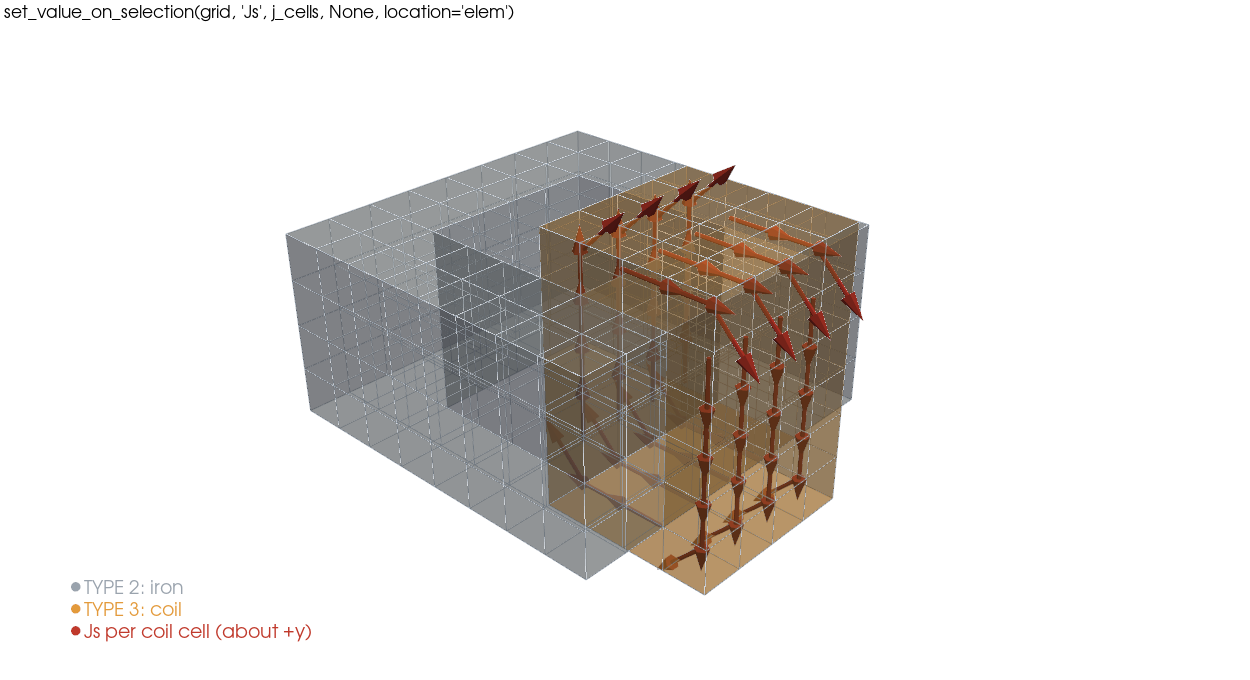

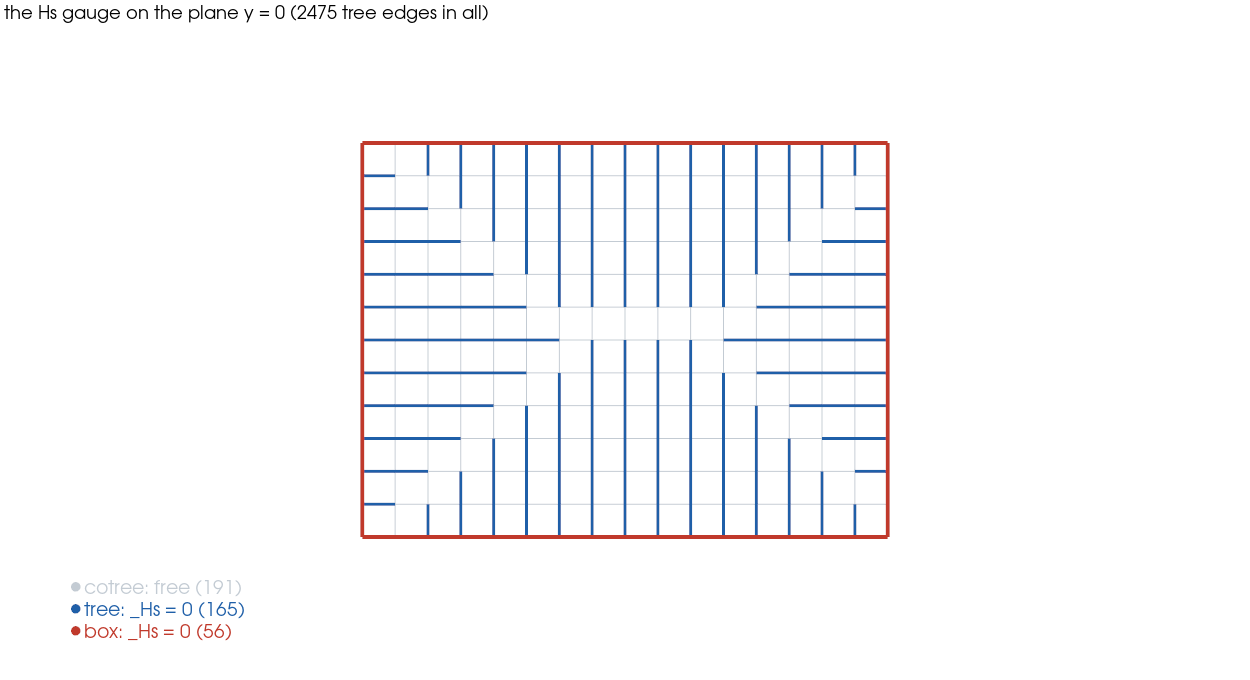

In [4]:
solver = new_solver("core_3D_phi", "look.log")
grid = solver.model.mesh
c = meshes.cell_centroids(grid)
selection.select(grid, "TYPE", 3, location="elem")
coil = selection.selected_ids(grid, "elem")
selection.set_value_on_selection(grid, "Js", coil_current(c, np.isin(np.arange(len(c)), coil))[coil], None, location="elem")
(view(grid, regions={2: "iron", 3: "coil"})
 .vectors(c[coil], meshes.array_values(grid, "Js", "elem")[coil], label="Js per coil cell (about +y)")
 .show("set_value_on_selection(grid, 'Js', j_cells, None, location='elem')",
       view=[(4.0, -4.0, 3.0), (0.3, 0.0, 0.0), (0, 0, 1)]))

selection.select_all(grid); selection.nsel_ext(grid)
box = selection.selected_ids(grid)
info = tree_gauge.tree_gauge(grid, array_name="_Hs")
selection.set_value_on_selection(grid, "_Hs", 0.0, 2)
xyz = meshes.points(grid)
mids, start, end = tree_gauge.edges(grid)
tree = meshes.array_values(grid, "TREE", "node")[mids] == 1
plane = (np.abs(xyz[start, 1]) < 1e-9) & (np.abs(xyz[end, 1]) < 1e-9)
on_box = np.isin(mids, box)
(view(grid, edges=False)
 .edges(start[plane & ~tree & ~on_box], end[plane & ~tree & ~on_box], "#c3cbd3", "cotree: free", width=1)
 .edges(start[plane & tree & ~on_box], end[plane & tree & ~on_box], "#1f5fa8", "tree: _Hs = 0")
 .edges(start[plane & on_box], end[plane & on_box], "#c0392b", "box: _Hs = 0", width=4)
 .show(f"the Hs gauge on the plane y = 0 ({info['num_tree']} tree edges in all)", view="xz"))
with quietly():
    solver.close()

## The magnetization curve of the frame

Static steps from 250 A-turns to 50 kA-turns with the B-H curve B = mu0 H + 1.8 H / (H + 300) (initial mu_r about
4800, saturating at 1.8 T), each solved by Newton from the previous step, and the same with a linear iron of
mu_r = 1000. A magnetic-circuit estimate: H = NI / l with the mean path l = 6 m, B = B(H) of the curve (no leakage).

Hs gauge: 10540 edges, 2475 tree edges fixed, 1282 root(s)
NI =     250 A-turns: B_leg = 0.254 T, Newton iterations 2
NI =     500 A-turns: B_leg = 0.445 T, Newton iterations 2
NI =    1000 A-turns: B_leg = 0.714 T, Newton iterations 2
NI =    2000 A-turns: B_leg = 1.023 T, Newton iterations 2
NI =    5000 A-turns: B_leg = 1.382 T, Newton iterations 3
NI =   10000 A-turns: B_leg = 1.558 T, Newton iterations 3
NI =   20000 A-turns: B_leg = 1.649 T, Newton iterations 3
NI =   50000 A-turns: B_leg = 1.699 T, Newton iterations 2


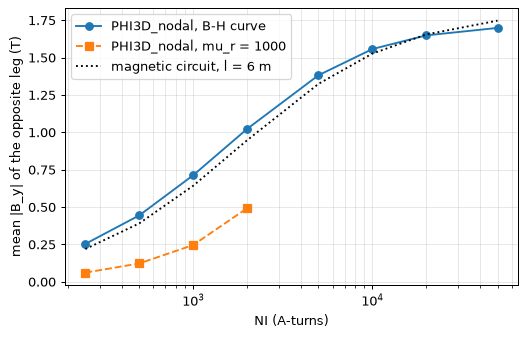

In [5]:
ni = np.array([250.0, 500.0, 1e3, 2e3, 5e3, 1e4, 2e4, 5e4])
nonlinear = run(ni, bh=True, log="nonlinear.log")
linear = run(ni[:4], bh=False, log="linear.log")
info = nonlinear["info"]
print(f"Hs gauge: {info['num_edges']} edges, {info['num_tree']} tree edges fixed, {info['num_roots']} root(s)")
for k, (n, b, it) in enumerate(zip(ni, nonlinear["B"], nonlinear["newton"])):
    print(f"NI = {n:7.0f} A-turns: B_leg = {b:.3f} T, Newton iterations {it}")

estimate = np.interp(ni / 6.0, BH[:, 0], BH[:, 1])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogx(ni, nonlinear["B"], "o-", label="PHI3D_nodal, B-H curve")
ax.semilogx(ni[:4], linear["B"], "s--", label="PHI3D_nodal, mu_r = 1000")
ax.semilogx(ni, estimate, "k:", label="magnetic circuit, l = 6 m")
ax.set_xlabel("NI (A-turns)"); ax.set_ylabel("mean |B_y| of the opposite leg (T)"); ax.grid(True, which="both", alpha=0.3)
ax.legend(); plt.show()

The flux in the opposite leg follows the magnetic-circuit estimate closely: below the knee the steep part of the
curve, above 10 kA-turns the saturation (the curves flatten at about 1.7 T; the leakage through the window and the
corners make the difference). The linear iron (mu_r = 1000, below the initial 4800 of the curve) grows without limit. Newton needs only a few
iterations per step (the law `bh_curve_h`: input H, output $\mu$, its tangent $d\mathbf{B}/d\mathbf{H}$).

## Hs given on the edges

Instead of solving $\mathbf{H}_s$, it may be **given**: `_Hs` on every edge, the circulations of any field with the
right curl, for example the Biot-Savart field of the coils, here the piecewise-linear field `t0` of the winding
($\mathbf{t}_0=f\,\mathbf{e}_y$, $f$ = NI over the leg section, falling to 0 across the winding: its curl is the coil
current). Circulations, not point values: their discrete curl is then exactly the flux of the current through each
mesh face (Stokes), and the cancellation in the iron stays exact. All the $\mathbf{H}_s$ rows are then eliminated:
only $\phi$ is solved (no tree, no `Js`).

In [6]:
given = run(ni, bh=True, hs_given=True, log="given.log")
for n, b1, b2 in zip(ni, nonlinear["B"], given["B"]):
    print(f"NI = {n:7.0f}: B_leg solved Hs {b1:.4f} T, given Hs {b2:.4f} T, difference {100 * (b2 / b1 - 1):+.2f} %")

NI =     250: B_leg solved Hs 0.2539 T, given Hs 0.2580 T, difference +1.60 %
NI =     500: B_leg solved Hs 0.4448 T, given Hs 0.4510 T, difference +1.40 %
NI =    1000: B_leg solved Hs 0.7135 T, given Hs 0.7215 T, difference +1.12 %
NI =    2000: B_leg solved Hs 1.0233 T, given Hs 1.0316 T, difference +0.81 %
NI =    5000: B_leg solved Hs 1.3822 T, given Hs 1.3881 T, difference +0.43 %
NI =   10000: B_leg solved Hs 1.5576 T, given Hs 1.5611 T, difference +0.22 %
NI =   20000: B_leg solved Hs 1.6493 T, given Hs 1.6508 T, difference +0.09 %
NI =   50000: B_leg solved Hs 1.6992 T, given Hs 1.7013 T, difference +0.12 %


The two agree within about a percent: the same current, two source fields differing by a gradient, which $\phi$
absorbs (up to the discretization: the solved $\mathbf{H}_s$ carries the solenoidal part of the cell-wise `Js`, the
given one exactly the winding current). The benchmark `closed_core` of the `formulations` suite compares both against
the A formulation: 1.9 % and 3.6 % on this mesh size.

Which to use: solving $\mathbf{H}_s$ needs only `Js` (any shape, any number of coils) and adds one unknown per edge of
the whole mesh; giving it needs a field whose circulations you can compute (a Biot-Savart integral per edge), and
removes those unknowns.

## The field in the saturated frame

|B| on the mid-plane z = 0 at 50 kA-turns: the legs are saturated (1.6-1.7 T); the outer corners of the frame carry
less flux (it takes the inner, shorter path), and some flux leaks into the window and around the coil (orange: the
coil).

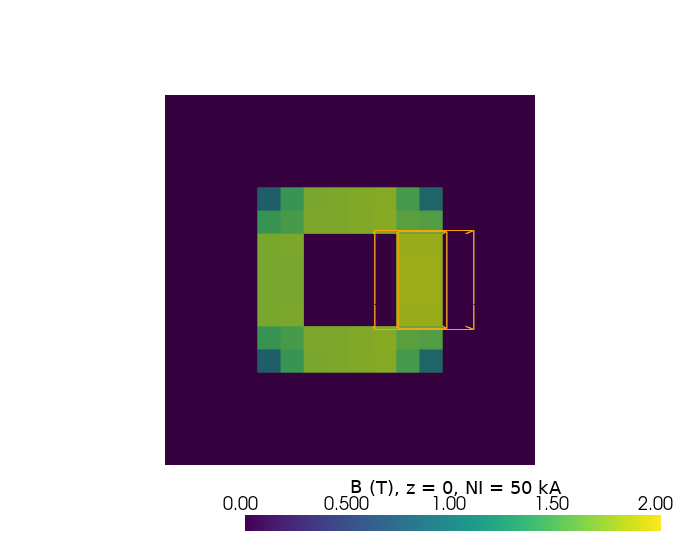

In [7]:
g = nonlinear["grid"]
g.cell_data["|B|"] = np.linalg.norm(g.cell_data["B"], axis=1)
p = pv.Plotter(window_size=(700, 560))
p.add_mesh(g.slice(normal="z", origin=(0, 0, 0.01)), scalars="|B|", cmap="viridis", clim=(0, 2.0),
           scalar_bar_args={"title": "|B| (T), z = 0, NI = 50 kA"})
p.add_mesh(g.threshold((3, 3), scalars="TYPE").extract_feature_edges(), color="orange")
p.view_xy(); p.show()

## Takeaways

* `PHI3D_nodal`: `Js` on `STRANDED_CONDUCTOR` cells, a tree gauge of `_Hs` rooted on the box plus `_Hs` = 0 on the
  box edges, one fixed `_PHI`; first order (`option2` = 1); static steps (`transient_effects` False).
* An iron loop around a current needs nothing special: no cut, no cancellation error.
* A B-H curve on the iron is the law `bh_curve_h` (`set_bh_curve` selects it for this type); Newton converges in a
  few iterations per load step.
* `_Hs` given on every edge (`tree_gauge.edges`, `tree_gauge.edge_circulations` of a known field) is the cheap
  variant when the source field is known.